In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

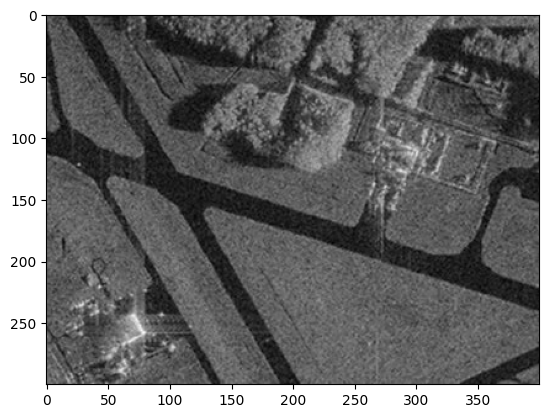

In [3]:
plt.imshow(image_gray, cmap="gray")

# Алгоритм разрастания регионов

In [4]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False
    

In [5]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
        
    return mask*255
    

In [6]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average,1, 10)

3
4
4
5
7
6
6
9
7
6
6
9
13
12
15
17
13
13
16
16
14
16
15
16
10
11
14
13
14
10
10
14
17
15
36
22
21
18
21
21
25
23
43
31
34
23
20
27
29
35
40
32
35
42
48
52
30
23
20
19
19
20
18
22
74
24
26
29
30
27
29
29
28
29
20
17
17
21
20
25
23
24
20
18
19
15
18
18
15
18
13
10
9
7
9
9
10
11
12
10
12
11
8
9
7
4
3
6
6
6
5
5
5
3
2
2
2
1
0


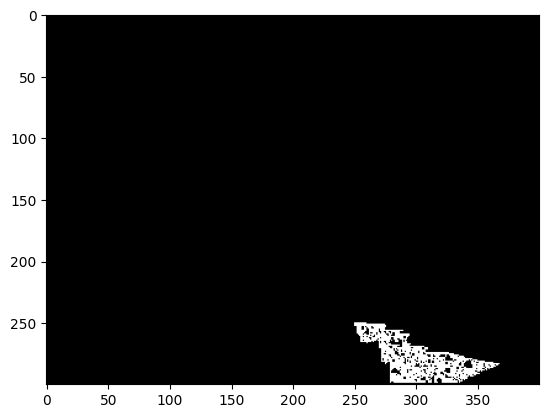

In [7]:
plt.imshow(mask, cmap="gray")

# K-means

In [8]:
# Define criteria = ( type, max_iter = 10 , epsilon = 1.0 )
# criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 10, 1.0)

In [9]:
flags = cv2.KMEANS_RANDOM_CENTERS

In [10]:
z = image_gray.reshape((-1,1))
# convert to np.float32
z = np.float32(z)
# define criteria, number of clusters(K) and apply kmeans()
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3
ret,label,center=cv2.kmeans(z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)
# Now convert back into uint8, and make original image
center = np.uint8(center)
res = center[label.flatten()]
res2 = res.reshape(image_gray.shape)

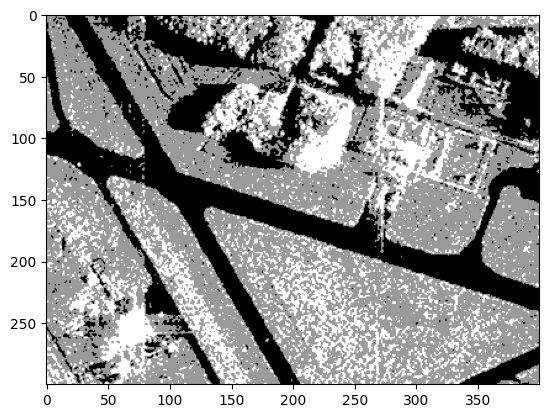

In [11]:
plt.imshow(res2, cmap="gray")

# Watershed+Distance transform

In [12]:
image = cv2.imread('oranges_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

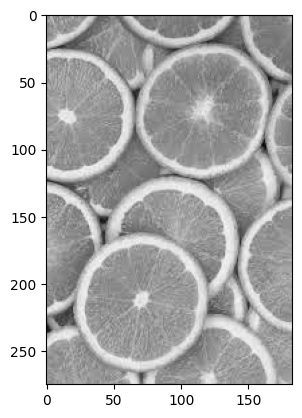

In [13]:
plt.imshow(image_gray, cmap="gray")

In [14]:
ret, thresh = cv2.threshold(image_gray,0,255, cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)

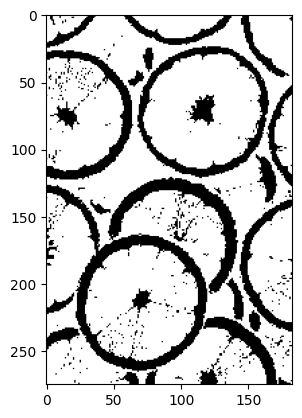

In [15]:
plt.imshow(thresh, cmap="gray")

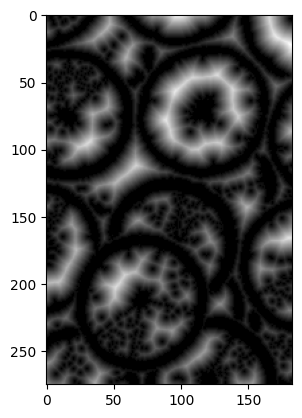

In [16]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

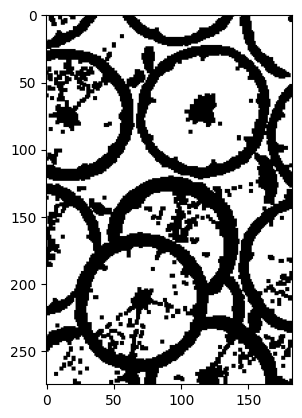

In [17]:
ret, sure_fg = cv2.threshold(dist, 0.1 * dist.max(), 255, cv2.THRESH_BINARY) 
plt.imshow(sure_fg, cmap="gray")

In [18]:
sure_fg = sure_fg.astype(np.uint8)

In [19]:
ret, markers = cv2.connectedComponents(sure_fg) 

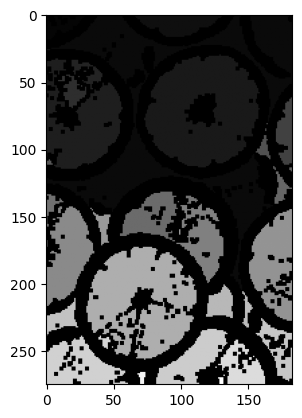

In [20]:
plt.imshow(markers, cmap="gray")

In [21]:
markers = cv2.watershed(image, markers)

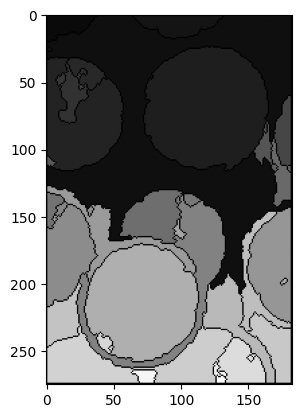

In [22]:
plt.imshow(markers, cmap="gray")

In [23]:
# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

## Решение домашнего задания

### 1. Подбор параметров Region Growing

Подбираем порог `T` для изображения `sar_1.jpg`. Сравним несколько масок и выберем подходящую по изображению.

2
1
0
3
4
4
5
7
6
6
9
7
6
6
9
13
12
15
17
13
13
16
16
14
16
15
16
10
11
14
13
14
10
10
14
17
15
36
22
21
18
21
21
25
23
43
31
34
23
20
27
29
35
40
32
35
42
48
52
30
23
20
19
19
20
18
22
74
24
26
29
30
27
29
29
28
29
20
17
17
21
20
25
23
24
20
18
19
15
18
18
15
18
13
10
9
7
9
9
10
11
12
10
12
11
8
9
7
4
3
6
6
6
5
5
5
3
2
2
2
1
0
3
5
5
7
9
9
11
14
16
15
19
22
26
28
28
22
20
20
24
34
38
41
47
44
47
49
56
50
52
47
53
62
59
62
63
64
60
65
74
71
79
77
79
79
85
85
88
90
58
65
49
47
49
46
46
43
44
44
44
42
42
42
39
36
38
42
42
44
40
35
39
45
41
30
36
41
38
37
37
35
37
37
37
40
44
34
35
40
38
32
32
31
28
29
33
32
33
30
32
33
30
29
31
32
28
30
29
30
26
28
28
30
26
25
25
26
23
25
19
16
16
18
19
20
16
18
18
18
14
10
12
15
19
14
13
13
13
13
12
12
11
9
9
9
8
8
7
5
0
3
5
5
8
12
11
13
16
20
20
22
25
26
29
31
27
29
34
36
42
43
44
47
49
51
53
55
55
56
60
61
63
68
67
69
73
72
75
77
80
83
86
85
85
92
90
93
94
48
46
46
46
45
45
45
45
45
45
45
44
44
45
44
43
43
45
45
44
44
43
44
43
43
37
42
43
41
41
42
41
4

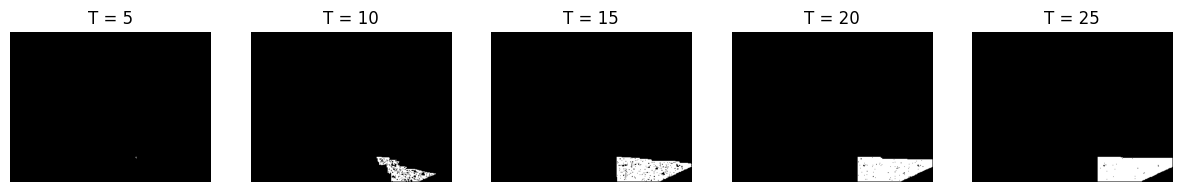

3
5
5
7
9
9
11
14
16
15
19
22
26
28
28
22
20
20
24
34
38
41
47
44
47
49
56
50
52
47
53
62
59
62
63
64
60
65
74
71
79
77
79
79
85
85
88
90
58
65
49
47
49
46
46
43
44
44
44
42
42
42
39
36
38
42
42
44
40
35
39
45
41
30
36
41
38
37
37
35
37
37
37
40
44
34
35
40
38
32
32
31
28
29
33
32
33
30
32
33
30
29
31
32
28
30
29
30
26
28
28
30
26
25
25
26
23
25
19
16
16
18
19
20
16
18
18
18
14
10
12
15
19
14
13
13
13
13
12
12
11
9
9
9
8
8
7
5
0


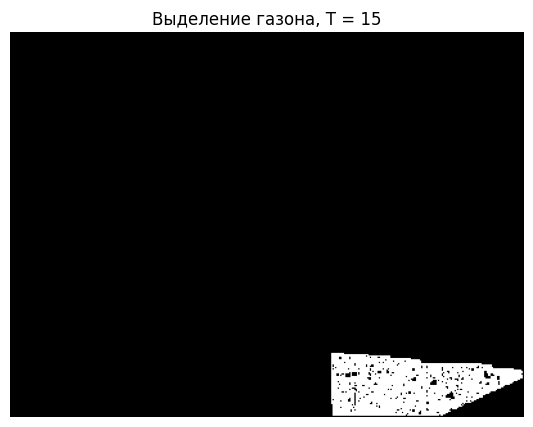

In [24]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

seed_point = (250, 250)
thresholds = [5, 10, 15, 20, 25]

fig, axes = plt.subplots(1, len(thresholds), figsize=(15, 4))
for ax, T in zip(axes, thresholds):
    mask = region_growing(image_gray, seed_point, homo_average, 1, T)
    ax.imshow(mask, cmap='gray')
    ax.set_title(f'T = {T}')
    ax.axis('off')
plt.show()

# Выбранный порог
mask = region_growing(image_gray, seed_point, homo_average, 1, 15)
plt.figure(figsize=(7, 5))
plt.imshow(mask, cmap='gray')
plt.title('Выделение газона, T = 15')
plt.axis('off');

### 2. Другой критерий однородности

Вместо сравнения со средним значением региона сравним яркость нового пикселя с яркостью соседнего пикселя, уже включённого в регион.

3
5
5
7
9
9
11
14
16
15
19
22
26
28
28
22
20
20
24
34
38
41
47
44
47
49
56
50
52
47
53
62
59
62
63
64
60
65
74
71
79
77
79
79
85
85
88
90
58
65
49
47
49
46
46
43
44
44
44
42
42
42
39
36
38
42
42
44
40
35
39
45
41
30
36
41
38
37
37
35
37
37
37
40
44
34
35
40
38
32
32
31
28
29
33
32
33
30
32
33
30
29
31
32
28
30
29
30
26
28
28
30
26
25
25
26
23
25
19
16
16
18
19
20
16
18
18
18
14
10
12
15
19
14
13
13
13
13
12
12
11
9
9
9
8
8
7
5
0
3
5
7
9
10
12
16
18
17
20
23
26
28
29
30
31
31
34
37
37
41
40
46
49
51
53
55
57
58
59
64
63
66
69
71
73
75
76
77
81
84
83
86
88
90
93
94
98
58
57
54
52
52
51
53
48
50
47
48
50
50
50
49
49
49
49
49
49
49
48
50
49
48
46
53
49
48
49
49
49
49
48
47
51
50
46
48
51
48
46
46
47
47
50
47
48
50
53
52
53
48
49
49
49
49
49
49
49
48
50
49
49
49
49
48
50
49
48
48
49
49
49
50
50
49
49
49
49
49
49
47
46
48
49
50
49
48
50
49
50
50
50
49
49
49
49
49
49
4
3
1
1
0


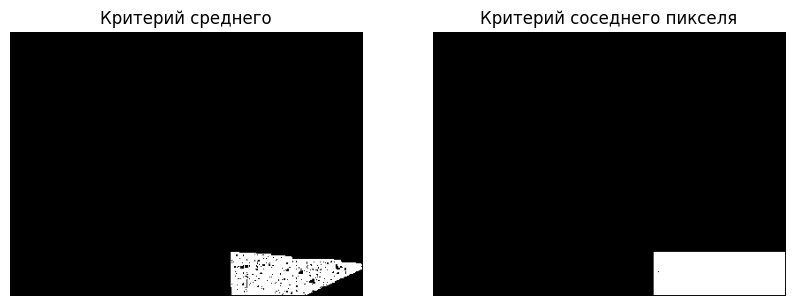

In [25]:
def homo_neighbor(img, mask, point, T):
    i, j = point
    neighbors = img[max(0, i-1):i+2, max(0, j-1):j+2]
    region = mask[max(0, i-1):i+2, max(0, j-1):j+2] > 0
    return np.any(np.abs(neighbors[region].astype(float) - float(img[i, j])) <= T)

mask_mean = region_growing(image_gray, seed_point, homo_average, 1, 15)
mask_neighbor = region_growing(image_gray, seed_point, homo_neighbor, 1, 15)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(mask_mean, cmap='gray')
axes[0].set_title('Критерий среднего')
axes[1].imshow(mask_neighbor, cmap='gray')
axes[1].set_title('Критерий соседнего пикселя')
for ax in axes:
    ax.axis('off')
plt.show()

При критерии среднего яркость пикселя сравнивается со средней яркостью всей выделенной области. Новый критерий проверяет сходство с уже включёнными соседями. Второй способ лучше учитывает локальные изменения яркости, но может распространяться дальше по плавно меняющимся областям.

### 3. Подсчёт пальм методом Watershed + Distance Transform

Количество выделенных пальм: 300


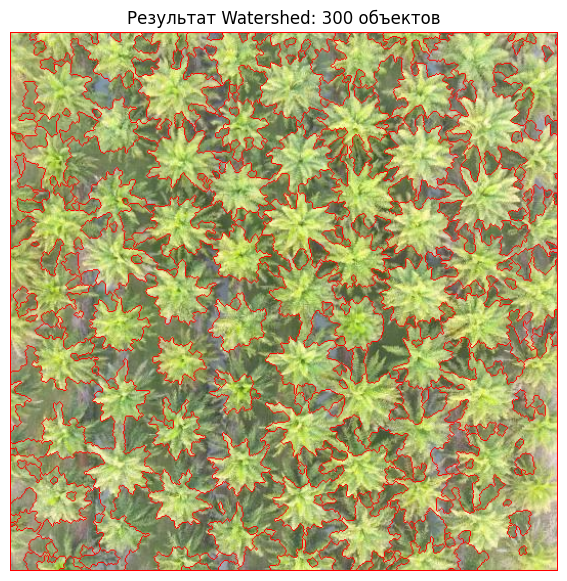

In [26]:
image = cv2.imread('palm_1.JPG')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Бинаризация и очистка маски
_, thresh = cv2.threshold(
    image_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
kernel = np.ones((3, 3), np.uint8)
thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Distance transform и внутренние маркеры объектов
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.1 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = np.uint8(sure_fg)

sure_bg = cv2.dilate(thresh, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Watershed
markers = cv2.watershed(image, markers)

# Число найденных объектов (метка -1 соответствует границам)
palm_count = len(np.unique(markers[markers > 1]))
print('Количество выделенных пальм:', palm_count)

result = image.copy()
result[markers == -1] = [0, 0, 255]

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f'Результат Watershed: {palm_count} объектов')
plt.axis('off');